[Python, Visually](https://johnfisher-ai.github.io/Python-Visual-Guides/) &nbsp;&rsaquo;&nbsp; [GeoPandas, Deep Dive](https://johnfisher-ai.github.io/Python-Visual-Guides/geopandas-deep-dive.html)

# Why GeoPandas &middot; Solutions


One way to do each task. Not the only way. If yours runs and does what was asked, yours is
right too.

In [1]:
from pathlib import Path

import numpy as np
import pandas as pd
import geopandas as gpd
import shapely
import matplotlib.pyplot as plt

COUNTRIES_URL = ("https://raw.githubusercontent.com/johnfisher-ai/Python-Visual-Guides/main/data/nordic-countries.geojson")
local_copy = Path("../../data/nordic-countries.geojson")
countries = gpd.read_file(local_copy if local_copy.exists() else COUNTRIES_URL)


weather_stations = pd.DataFrame({
    "name": ["Bergen", "Oslo", "Svalbard", "Tromso", "Kirkenes"],
    "latitude": [60.39, 59.91, 78.22, 69.65, 69.73],
    "longitude": [5.32, 10.75, 15.65, 18.96, 30.05],
})


def mainland_norway():
    """Norway's outline south of 74 degrees north, without Svalbard, in UTM zone 33N."""
    parts = countries[countries["ADMIN"] == "Norway"].to_crs(25833).explode()
    return parts[parts.geometry.bounds["maxy"] < 8_200_000].union_all()


def station_network(n=300, seed=2026):
    """A made-up register of weather stations on mainland Norway, one row each."""
    rng = np.random.default_rng(seed)
    land = mainland_norway()
    x_min, y_min, x_max, y_max = land.bounds
    east, north = [], []
    while len(east) < n:
        x, y = rng.uniform(x_min, x_max), rng.uniform(y_min, y_max)
        if land.contains(shapely.Point(x, y)):
            east.append(x)
            north.append(y)
    lonlat = gpd.GeoSeries(gpd.points_from_xy(east, north), crs=25833).to_crs(4326)
    return pd.DataFrame({
        "station": [f"NS{i:03d}" for i in range(1, n + 1)],
        "latitude": lonlat.y.round(4).to_numpy(), "longitude": lonlat.x.round(4).to_numpy(),
        "elevation_m": np.clip(rng.gamma(1.6, 220, n), 2, 1900).round(0).astype(int),
        "owner": rng.choice(["met", "road", "airport", "private"], n, p=[0.4, 0.3, 0.1, 0.2]),
        "installed": rng.integers(1950, 2025, n),
    })


DISTRICT_CENTERS = {"South": (8.0, 58.6), "East": (10.8, 60.5), "West": (6.0, 60.8), "Mid": (11.0, 63.6),
                    "North": (14.5, 67.0), "Far North": (19.0, 69.4), "Northeast": (25.5, 70.0),
                    "Svalbard": (16.0, 78.5)}


def forecast_districts():
    """Eight made-up forecast districts that cover Norway, in UTM zone 33N."""
    norway = countries[countries["ADMIN"] == "Norway"].to_crs(25833).geometry.iloc[0]
    centers = gpd.GeoSeries(gpd.points_from_xy(*zip(*DISTRICT_CENTERS.values())), crs=4326).to_crs(25833)
    cells = shapely.voronoi_polygons(shapely.MultiPoint(list(centers)),
                                     extend_to=shapely.box(*norway.buffer(200_000).bounds)).geoms
    names = [next(name for name, center in zip(DISTRICT_CENTERS, centers) if cell.contains(center))
             for cell in cells]
    districts = gpd.GeoDataFrame({"district": names}, geometry=[cell.intersection(norway) for cell in cells],
                                 crs=25833)
    return districts.set_index("district").loc[list(DISTRICT_CENTERS)].reset_index()


network = station_network()
districts = forecast_districts()
print("geopandas", gpd.__version__, "| shapely", shapely.__version__, "|", len(countries), "countries,",
      len(network), "made-up stations,", len(districts), "made-up districts")

geopandas 1.2.0 | shapely 2.2.0 | 5 countries, 300 made-up stations, 8 made-up districts


The worked examples' tables, rebuilt here so that each answer runs on its own.

In [2]:
stations = gpd.GeoDataFrame(
    network, geometry=gpd.points_from_xy(network["longitude"], network["latitude"]), crs=4326
)
joined = gpd.sjoin(stations.to_crs(districts.crs), districts, how="left")
named = gpd.GeoDataFrame(
    weather_stations,
    geometry=gpd.points_from_xy(weather_stations["longitude"], weather_stations["latitude"]),
    crs=4326,
)

**1.** Count the network stations in the Mid district by `owner`, using `joined`.

In [3]:
joined[joined["district"] == "Mid"].groupby("owner").size()

owner
airport     8
met        24
private    10
road       27
dtype: int64

`groupby("owner").size()` counts rows, here the Mid district's 69 stations split by who runs them.

**2.** Print how many network stations were installed before 1970 in each district, with Svalbard shown as 0.

In [4]:
early = joined[joined["installed"] < 1970]
early.groupby("district").size().reindex(districts["district"], fill_value=0)

district
South         7
East         17
West         11
Mid          16
North         6
Far North     5
Northeast    12
Svalbard      0
dtype: int64

`reindex` puts the districts in their own order and gives Svalbard, which has no stations, a 0.

**3.** Convert `countries` to UTM zone 33N and print Norway's area in square kilometers, rounded to a whole number.

In [5]:
norway = countries[countries["ADMIN"] == "Norway"].to_crs(25833)
print(round(norway.area.iloc[0] / 1e6))

386897


In a CRS measured in meters the area is in square meters, so dividing by a million gives square kilometers. The figure includes Svalbard and every island in the outline.

**4.** Find the network station farthest from Oslo, and print its id, its district and its distance in kilometers.

In [6]:
oslo = named.to_crs(25833).geometry.iloc[1]
far = joined.assign(km=(joined.distance(oslo) / 1000).round().astype(int)).nlargest(1, "km")
print(far[["station", "district", "km"]].to_string(index=False))

station  district   km
  NS197 Northeast 1484


`joined` is already in UTM zone 33N, so `distance` is in meters. `nlargest` keeps the station with the largest distance.

**5.** Draw a map of the Mid district alone, with its outline and its stations.

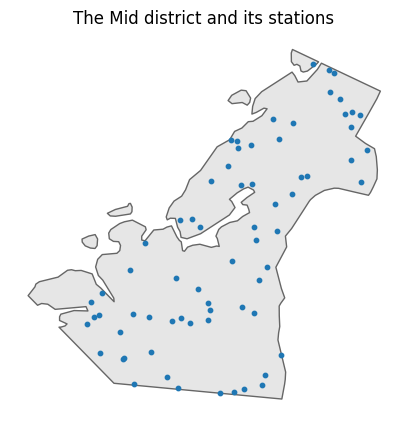

In [7]:
mid = districts[districts["district"] == "Mid"]
fig, ax = plt.subplots(figsize=(5, 5))
mid.plot(ax=ax, color="0.9", edgecolor="0.4")
joined[joined["district"] == "Mid"].plot(ax=ax, markersize=10, color="tab:blue")
ax.set_axis_off()
ax.set_title("The Mid district and its stations")
plt.show()

Both layers are in UTM zone 33N, so they line up on the same axes.

---

&#8592; **Back to:** [Why GeoPandas](https://colab.research.google.com/github/johnfisher-ai/Python-Visual-Guides/blob/main/notebooks/geopandas-deep-dive/01-why-geopandas.ipynb)  &nbsp;&middot;&nbsp;  [GeoPandas, Deep Dive Notebooks](https://johnfisher-ai.github.io/Python-Visual-Guides/geopandas-deep-dive.html)
